# Data analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})

robot = pd.read_csv("../data/raw/wall_robot.csv")
ctg = pd.read_csv("../data/raw/cardiotocography.csv")
cov = pd.read_csv("../data/raw/covertype.csv.gz")
data = {"Wall robot": robot, "Cardiotocography": ctg, "Covertype": cov}
{k: v.shape for k, v in data.items()}

{'Wall robot': (5456, 25),
 'Cardiotocography': (2126, 36),
 'Covertype': (581012, 55)}

## Class imbalance

In [2]:
pd.DataFrame({k: {"classes": v["class"].nunique(),
                  "largest": v["class"].value_counts().max(),
                  "smallest": v["class"].value_counts().min(),
                  "ratio": round(v["class"].value_counts().max() / v["class"].value_counts().min(), 1)}
              for k, v in data.items()}).T

,classes,largest,smallest,ratio
Wall robot,4.0,2205.0,328.0,6.7
Cardiotocography,10.0,579.0,53.0,10.9
Covertype,7.0,283301.0,2747.0,103.1


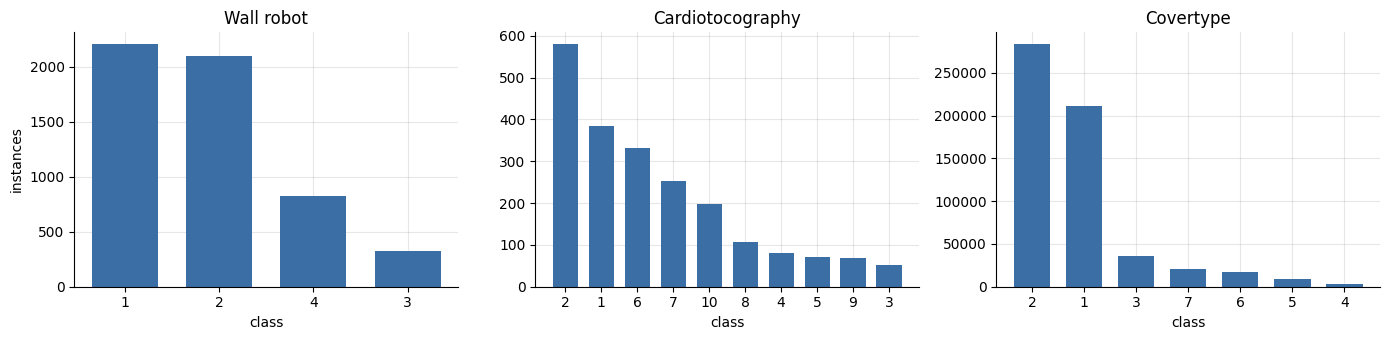

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (name, df) in zip(axes, data.items()):
    counts = df["class"].value_counts()
    ax.bar(counts.index.astype(str), counts.values, color="#3b6ea5", width=0.7)
    ax.set_title(name)
    ax.set_xlabel("class")
axes[0].set_ylabel("instances")
plt.tight_layout()

## Missing values and duplicates

In [4]:
pd.DataFrame({k: {"missing": int(v.isna().sum().sum()),
                  "duplicate rows": int(v.duplicated().sum())}
              for k, v in data.items()}).T

,missing,duplicate rows
Wall robot,0,0
Cardiotocography,0,11
Covertype,0,0


## Wall robot

In [5]:
robot.drop(columns="class").describe().T[["min", "max", "mean", "std"]].round(2)

,min,max,mean,std
V1,0.40,5.00,1.47,0.80
V2,0.44,5.03,2.33,1.41
V3,0.47,5.03,2.49,1.25
V4,0.83,5.02,2.80,1.31
V5,1.12,5.00,2.96,1.34
V6,1.11,5.00,2.89,1.28
V7,1.12,5.01,3.35,1.41
V8,0.86,5.09,2.54,1.11
V9,0.84,5.00,3.13,1.36
V10,0.81,5.02,2.83,1.31


In [6]:
c = robot.drop(columns="class").corr().abs().to_numpy().copy()
np.fill_diagonal(c, 0)
c.max()

np.float64(0.6268029981803365)

## Cardiotocography
### Leakage

In [7]:
ind = ctg[[f"V{i}" for i in range(26, 36)]]
pd.crosstab(ind.idxmax(axis=1), ctg["class"])

class,1,2,3,4,5,6,7,8,9,10
row_0,,,,,,,,,,
V26,384,0,0,0,0,0,0,0,0,0
V27,0,579,0,0,0,0,0,0,0,0
V28,0,0,53,0,0,0,0,0,0,0
V29,0,0,0,81,0,0,0,0,0,0
V30,0,0,0,0,72,0,0,0,0,0
V31,0,0,0,0,0,332,0,0,0,0
V32,0,0,0,0,0,0,252,0,0,0
V33,0,0,0,0,0,0,0,107,0,0
V34,0,0,0,0,0,0,0,0,69,0


In [8]:
(ind.sum(axis=1) == 1).all()

np.True_

### V4 vs V5

In [9]:
(ctg["V4"] == ctg["V5"]).all()

np.True_

### V1, V2, V3

In [10]:
ctg[["V1", "V2", "V3"]].head(15).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
V1,23,45,45,45,45,45,45,30,30,30,30,30,5,5,5
V2,240,5,177,411,533,0,240,62,120,181,0,57,52,531,0
V3,357,632,779,1192,1147,953,953,679,779,1192,1199,1074,840,1192,1199


In [11]:
ctg["V1"].nunique()

48

### Skew

In [12]:
ctg_feats = ctg.drop(columns=["class", "V1", "V2", "V3", "V5"] + [f"V{i}" for i in range(26, 36)])
ctg_feats.skew().sort_values(ascending=False).round(2).head(8)

V14    17.35
V7      9.43
V15     4.24
V20     3.92
V24     3.22
V11     2.20
V13     1.82
V6      1.66
dtype: float64

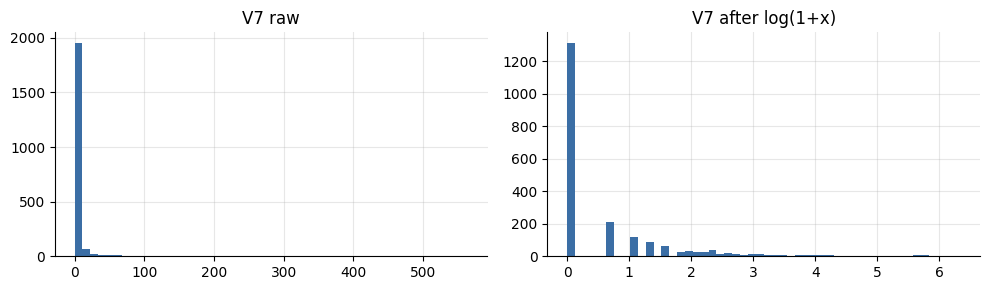

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(ctg["V7"], bins=50, color="#3b6ea5")
axes[0].set_title("V7 raw")
axes[1].hist(np.log1p(ctg["V7"]), bins=50, color="#3b6ea5")
axes[1].set_title("V7 after log(1+x)")
plt.tight_layout()

In [14]:
ctg[["V7", "V15", "V20", "V24"]].apply(np.log1p).skew().round(2)

V7     2.03
V15    3.50
V20    1.73
V24    0.16
dtype: float64

### Correlations

In [15]:
c = ctg_feats.corr().abs()
pairs = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack()
pairs[pairs > 0.9].round(3)

V21  V23    0.933
V22  V23    0.948
dtype: float64

In [16]:
ctg_feats.shape[1]

21

## Covertype

In [17]:
cont = cov.columns[:10]
cov[cont].describe().T[["min", "max", "mean", "std"]].round(1)

,min,max,mean,std
Elevation,1859.0,3858.0,2959.4,280.0
Aspect,0.0,360.0,155.7,111.9
Slope,0.0,66.0,14.1,7.5
Horizontal_Distance_To_Hydrology,0.0,1397.0,269.4,212.5
Vertical_Distance_To_Hydrology,-173.0,601.0,46.4,58.3
Horizontal_Distance_To_Roadways,0.0,7117.0,2350.1,1559.3
Hillshade_9am,0.0,254.0,212.1,26.8
Hillshade_Noon,0.0,254.0,223.3,19.8
Hillshade_3pm,0.0,254.0,142.5,38.3
Horizontal_Distance_To_Fire_Points,0.0,7173.0,1980.3,1324.2


In [18]:
wild = [c for c in cov.columns if c.startswith("Wilderness")]
soil = [c for c in cov.columns if c.startswith("Soil")]
len(wild), len(soil), (cov[wild].sum(axis=1) == 1).all(), (cov[soil].sum(axis=1) == 1).all()

(4, 40, np.True_, np.True_)

In [19]:
cov[soil].sum().sort_values().head(5)

Soil_Type_14      3.0
Soil_Type_6     105.0
Soil_Type_35    119.0
Soil_Type_7     179.0
Soil_Type_36    298.0
dtype: float64

### Subsample size

In [20]:
frac = cov["class"].value_counts().min() / len(cov)
pd.DataFrame({"n": [10_000, 15_000, 20_000],
              "smallest class": [round(n * frac) for n in [10_000, 15_000, 20_000]],
              "in test (20%)": [round(n * frac * 0.2) for n in [10_000, 15_000, 20_000]]})

,n,smallest class,in test (20%)
0,10000,47,9
1,15000,71,14
2,20000,95,19
